In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [22]:
mov_ind = 4
thresh = 0.8

In [23]:
load_path = f'saved/M_masked_mov{mov_ind}_thresh{thresh}.pkl'
M = ds.load_dataset(load_path)

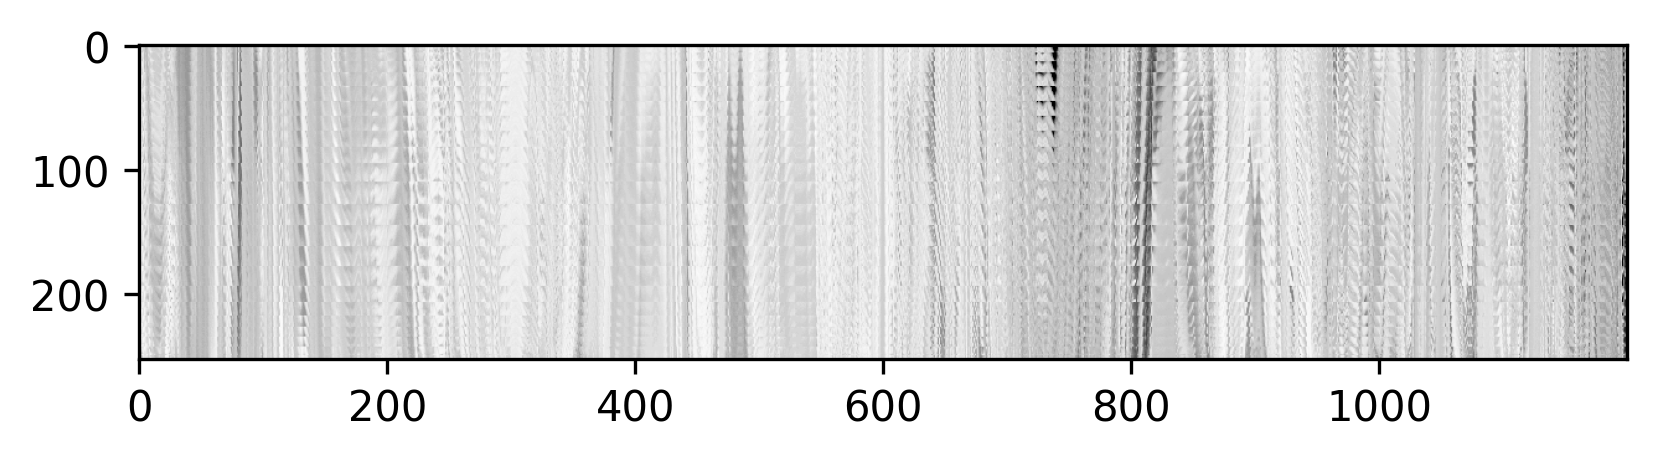

In [24]:
plt.subplots(dpi=300)
plt.imshow(M.X, cmap='Greys')

# Direct test

In [161]:
N_training_repeats = 1
cg_params = {
    "order": 1,
    "output_dim": 93
}

critic_params = {
    "hidden_dim": 10,
    "embed_dim": 10,
    "layers": 5,
    "activation": "tanh",
}

opt_params = {"track_quantities": False, "quiet": True, "iterations": 100}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

## Prepare data

In [162]:
M.reset()
V, E = M.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [163]:
experiment_dims = (N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)


for training_repeat in tqdm(range(N_training_repeats)):
    coarse_grainer = mds.PolynomialLayer(**cg_params)
    critic_function = mds.SeparableCritic(**critic_params)

    # make training and test subsets
    V.reset()
    E.reset()
    current_train_points, current_test_points = tools.generate_train_test_indices(
        V.P, train_fraction
    )
    V.subset_points(current_train_points)
    E.subset_points(current_train_points)
    train_points[training_repeat] = current_train_points
    test_points[training_repeat] = current_test_points

    # Train current
    als.IB(
        X=V.X,
        Y=E.X,
        coarse_grainer=coarse_grainer,
        critic_function=critic_function,
        **opt_params
    )

    # Measure InfoNCE for train
    T_train = coarse_grainer(V.X.T).numpy().T
    mi_train = als.MI_NCE(
        X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
    )
    mi_averages_train[training_repeat] = mi_train["mi"]
    mi_stdevs_train[training_repeat] = mi_train["mi_stdev"]

    # Measure InfoNCE for test
    V.reset()
    E.reset()
    V.subset_points(current_test_points)
    E.subset_points(current_test_points)
    T_test = coarse_grainer(V.X.T).numpy().T
    mi_test = als.MI_NCE(
        X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
    )
    mi_averages_test[training_repeat] = mi_test["mi"]
    mi_stdevs_test[training_repeat] = mi_test["mi_stdev"]

    coarse_grainer_array[training_repeat] = coarse_grainer
    critic_function_array[training_repeat] = critic_function

100%|██████████| 1/1 [00:02<00:00,  2.23s/it]


In [164]:
mi_averages_test

array([-8.32557678e-07])

In [165]:
mi_averages_train

array([-1.97029114e-06])

# IB curve

## Params

In [ ]:
# K_array = np.arange(10) + 1
K_array=np.array([10,200])
N_training_repeats = 2
cg_params = {
    "order": 1,
}
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1
# neuron_inds = np.sort(sample(list(np.arange(93)), k=50))

# Put variable names here for parameters we want saved.
experiment_configuration_variables = {'mi_measurement_params','meta_neuron_array', 'N_training_repeats', 'cg_params', 'critic_params', 'opt_params', 'V_width', 'V_E_buffer', 'E_width', 'train_fraction', 'samp_keep', 'neuron_inds'}

In [61]:
K_array

array([ 10, 200])

## Prepare data

In [62]:
M.reset()
# M.trim(20)  # remove first 20 frames from each trial
V, E = M.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [63]:
experiment_dims = (len(K_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)


for i, N_meta_neurons in tqdm(enumerate(K_array)):
    for training_repeat in range(N_training_repeats):
        coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, **cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[i, training_repeat] = current_train_points
        test_points[i, training_repeat] = current_test_points

        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[i, training_repeat] = mi_train["mi"]
        mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[i, training_repeat] = mi_test["mi"]
        mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        coarse_grainer_array[i, training_repeat] = coarse_grainer
        critic_function_array[i, training_repeat] = critic_function

2it [00:04,  2.26s/it]


In [64]:
data = Namespace(**locals())

In [65]:
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)

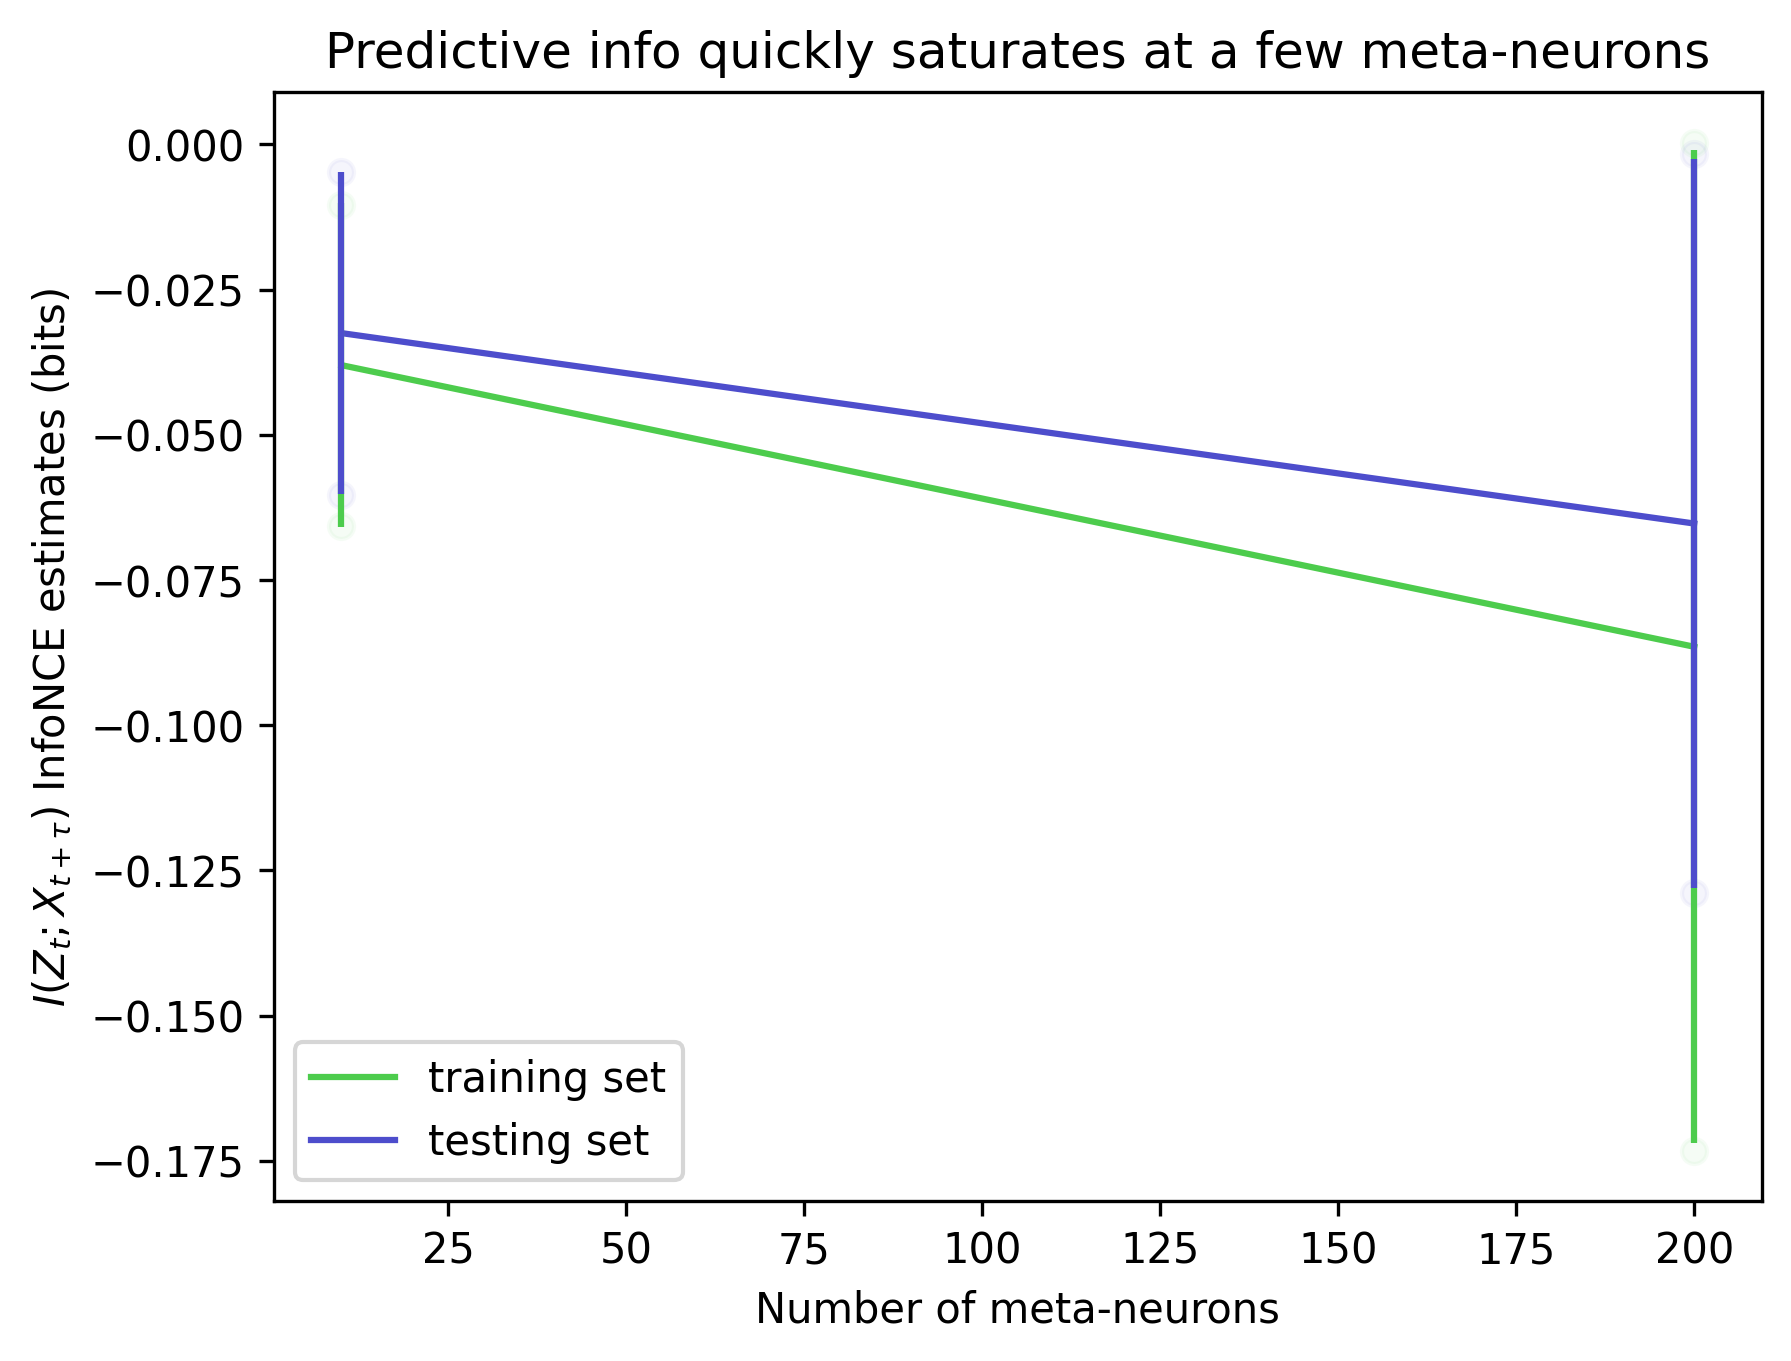

In [ ]:
x = data.K_array

c1 = 0.3
c2 = 0.8
alp = 0.05
plt.figure(dpi=300)
plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='training set')
plt.plot(x, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='testing set');
plt.plot(x, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))
# plt.ylim(ymin=0)
plt.ylabel(r'$I(Z_{t};X_{t+\tau})$ InfoNCE estimates (bits)')
plt.legend();